# Observation-dependent acquisition on a 2D example

We want to reconstruct an unknown function $f$ on $[0,1]^2$ from few noisy measurements.
A standard rule measures next where the GP posterior variance $s^2(x)$ is largest, which is
equivalent to maximizing EIG when the noise is fixed. This rule has two shortcomings:

1. **It ignores the observations.** With fixed hyperparameters, $s^2(x)$ depends on where we have
   measured but not on the measured values.
2. **It is biased towards the boundary.** Points near the boundary have fewer neighbours, so their
   variance remains high.

This notebook illustrates both effects, and the two corrections proposed in the paper, on the
Gramacy–Lee function.

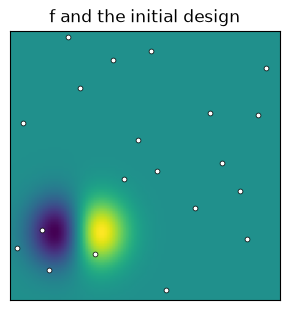

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import torch

from warp_gp.evaluate import onenn_trajectory, true_field
from warp_gp.gp import default_lengthscale, posterior_variance
from warp_gp.gp import grad_posterior_mean
from warp_gp.loop import run, setup
from warp_gp.equalizer import geometric_equalizer
from warp_gp.warp import build_reconstruction_warp, design_density

fn, D, noise, X, y, _ = setup("grlee08", seed=0)  # standardized f, noise variance, 20 initial Sobol points
ell = default_lengthscale(D)

n = 100
g1 = torch.linspace(0, 1, n)
G = torch.stack(torch.meshgrid(g1, g1, indexing="xy"), -1).reshape(-1, 2)  # evaluation grid


def show(ax, values, title, X=X, best=False):
    ax.imshow(values.reshape(n, n).detach(), origin="lower", extent=(0, 1, 0, 1), cmap="viridis")
    ax.scatter(*X.T, c="white", s=12, edgecolors="k", linewidths=0.5)
    if best:
        ax.scatter(*G[values.argmax()], marker="*", s=250, c="red", edgecolors="k", clip_on=False)
    ax.set(title=title, xticks=[], yticks=[])


fig, ax = plt.subplots(figsize=(3.5, 3.5))
show(ax, fn(G), "f and the initial design")

## The variance is largest at the boundary

The red star marks the point that variance maximization selects next. It lies in a corner, far
from the region where the function varies.

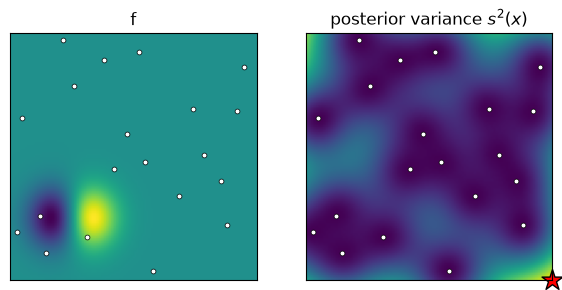

In [2]:
s2 = posterior_variance(X, G, noise, ell)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
show(axes[0], fn(G), "f")
show(axes[1], s2, "posterior variance $s^2(x)$", best=True)

## Correction 1: the geometric equalizer

The reference variance $\bar v_N(x)$ is the posterior variance at $x$ averaged over space-filling
designs of the same size $N$. It depends only on the domain, the kernel and $N$, and it increases
towards the boundary. The equalizer $g(x) = \min\big(1, \bar v_N(\text{centre}) / \bar v_N(x)\big)$
down-weights the boundary, and the next point maximizes $g(x)\,s^2(x)$.

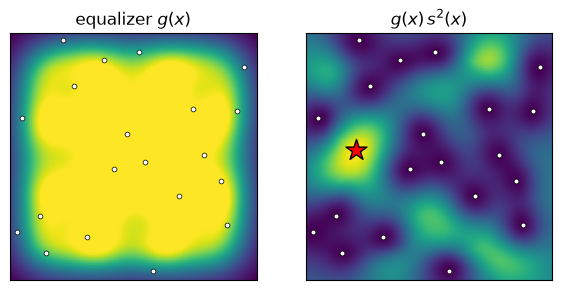

In [3]:
g = geometric_equalizer(G, len(X), D, ell, noise)

fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
show(axes[0], g, "equalizer $g(x)$")
show(axes[1], g * s2, "$g(x)\\,s^2(x)$", best=True)

## Correction 2: the reconstruction warp

To use the observations, we ask where measurements are most useful for reconstruction. For
nearest-neighbour reconstruction, the design density that minimizes the squared error is
$\rho^*(x) \propto \|\nabla f(x)\|^{2D/(D+2)}$. We replace $f$ by the posterior mean $\mu$ and add a
uniform floor, which gives $\hat\rho(x) = 1 + (\|\nabla\mu(x)\| / c)^{2D/(D+2)}$, where $c$ is the
root-mean-square gradient.

A Knothe–Rosenblatt map $T$ transports $\hat\rho$ to the uniform distribution. Measuring the
variance in the warped coordinates $T(x)$ makes acquisition distribute points according to
$\hat\rho$. The map is recomputed from $\mu$ in every round and requires no training.

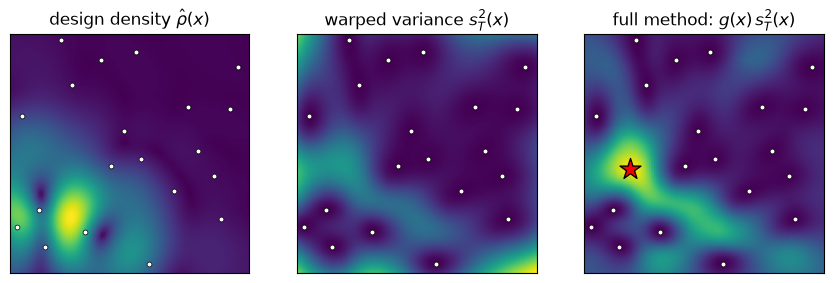

In [4]:
rho = design_density(grad_posterior_mean(X, y, G, noise, ell).norm(dim=1), D)
T = build_reconstruction_warp(X, y, noise, ell, D)
s2_T = posterior_variance(X, G, noise, ell, warp=T)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))
show(axes[0], rho, "design density $\\hat\\rho(x)$")
show(axes[1], s2_T, "warped variance $s_T^2(x)$")
show(axes[2], g * s2_T, "full method: $g(x)\\,s_T^2(x)$", best=True)

## Sequential acquisition

We run 60 rounds of each rule from the same initial design and score each design by its
1-nearest-neighbour reconstruction error. Farthest-point sampling (FPS) serves as a
space-filling reference.

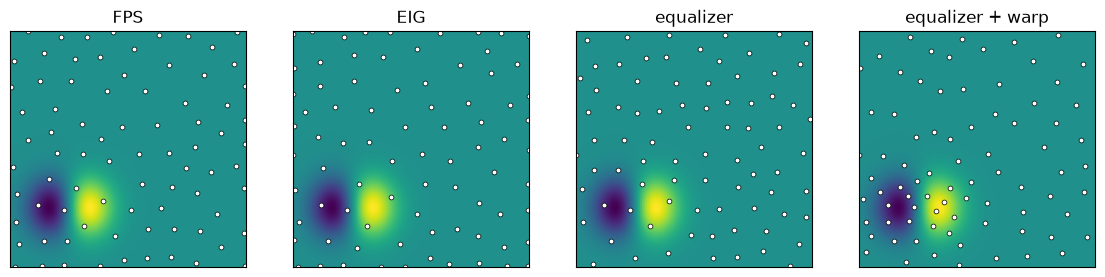

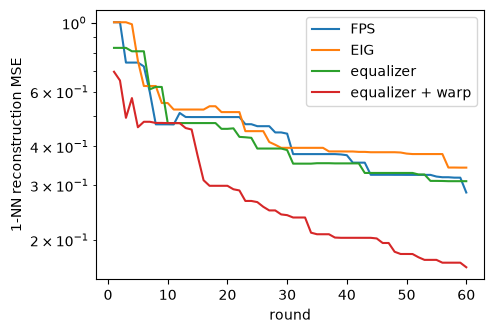

In [5]:
methods = {"fps": "FPS", "eig": "EIG", "eq": "equalizer", "eq_warp": "equalizer + warp"}
T_test, f_test, f_np = true_field("grlee08")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
errors = {}
for ax, (m, label) in zip(axes, methods.items()):
    X0, picks, _ = run("grlee08", seed=0, method=m, rounds=60)
    show(ax, fn(G), label, X=torch.cat([X0, picks]))
    errors[label] = onenn_trajectory(X0, picks, T_test, f_test, f_np)

fig, ax = plt.subplots(figsize=(5, 3.5))
for label, e in errors.items():
    ax.plot(range(1, 61), e, label=label)
ax.set(yscale="log", xlabel="round", ylabel="1-NN reconstruction MSE")
ax.legend()

FPS and EIG place many points on the boundary, and the equalizer moves points towards the
interior. Adding the warp concentrates the points where the function varies and clearly lowers
the reconstruction error. This example uses a single seed in two dimensions; the paper reports
averages over ten seeds on sixteen synthetic and two real-data benchmarks.

The experiments in the paper are run with `experiments/run.py` and summarized with
`experiments/table.py`.